# FER-2013 Facial Emotion Recognition — Appearance CNN
**Project:** Comparing Facial Appearance and Landmark Features for Emotion Recognition

This notebook is responsible **only for the appearance-based CNN branch**.
The geometry/landmark branch is maintained separately in `Geometry_Branch.ipynb`.

The notebook is configured for the project structure:

```text
MiniProject/
├── data/FER-2013/
├── models/
├── results/
├── fusion/
├── assets/
└── ...
```

The notebook supports the existing FER-2013 image-folder layout (`train/<emotion>` and
`test/<emotion>`). If a trained CNN already exists in `models/`, it is loaded and
**training is skipped**. The notebook always regenerates validation/test probability
artifacts needed by the decision-level fusion stage.


## Cell 1 · Install packages (run once)

In [1]:
# Run once if the environment is missing dependencies:
# %pip install -q "tensorflow>=2.13" "numpy<2" opencv-contrib-python scikit-learn matplotlib pandas

## Cell 2 · Imports, configuration and hyper-parameters
Every tunable setting lives here.

In [2]:
import sys
import tensorflow as tf

print("Python path:", sys.executable)
print("TensorFlow version:", tf.__version__)

Python path: c:\Users\HP\AppData\Local\Programs\Python\Python314\python.exe
TensorFlow version: 2.22.0-rc0


In [3]:
import os, json, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# ------------------------- project paths -------------------------
NOTEBOOK_DIR = Path.cwd()

# The notebook lives in MiniProject/, but this also works if launched from
# MiniProject/fusion or another child directory.
PROJECT_CANDIDATES = [
    NOTEBOOK_DIR,
    NOTEBOOK_DIR.parent,
    Path(r"C:\Users\HP\Documents\MiniProject"),
]

PROJECT_DIR = next(
    (
        p for p in PROJECT_CANDIDATES
        if (p / "data").is_dir() and (p / "models").is_dir()
    ),
    NOTEBOOK_DIR,
)

DATA_CANDIDATES = [
    PROJECT_DIR / "data" / "FER-2013",
    PROJECT_DIR / "fer2013",
    NOTEBOOK_DIR / "data" / "FER-2013",
    NOTEBOOK_DIR / "fer2013",
]

DATA_ENV = os.environ.get("ER_DATA")
if DATA_ENV:
    DATA_DIR = Path(DATA_ENV)
else:
    DATA_DIR = next(
        (
            p for p in DATA_CANDIDATES
            if (p / "train").is_dir() and (p / "test").is_dir()
        ),
        DATA_CANDIDATES[0],
    )

# Keep generated CNN handoff files with the existing project artifact structure.
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_PRED_DIR = RESULTS_DIR / "predictions"
RESULTS_CM_DIR = RESULTS_DIR / "confusion_matrices"
RESULTS_EXP_DIR = RESULTS_DIR / "experiments"
CACHE_DIR = PROJECT_DIR / "cache"

for d in (
    ARTIFACT_DIR,
    RESULTS_DIR,
    RESULTS_PRED_DIR,
    RESULTS_CM_DIR,
    RESULTS_EXP_DIR,
    CACHE_DIR,
):
    d.mkdir(parents=True, exist_ok=True)

# --------------------------- general settings ---------------------------
SEED            = 42
BATCH_SIZE      = 64
VAL_FRACTION    = 0.10
LABEL_SMOOTHING = 0.10
L2_WEIGHT       = 1e-4

# --------------------- appearance CNN architecture ----------------------
FILTERS         = (64, 128, 256, 512)
CONV_PER_BLOCK  = (2, 2, 3, 3)
KERNEL_SIZE     = 3
ACTIVATION      = "relu"
DROPOUT_CONV    = (0.25, 0.25, 0.30, 0.35)
DENSE_UNITS     = (512, 256)
DROPOUT_DENSE   = (0.50, 0.40)
CNN_LR          = 1e-3
CNN_EPOCHS      = 40
PATIENCE        = 18

# ---------------------- trained-model reuse ----------------------
# False = load the existing trained CNN whenever it is available.
# True  = intentionally retrain from scratch.
FORCE_RETRAIN = False

MODEL_CANDIDATES = [
    PROJECT_DIR / "models" / "appearance_cnn_fixed.keras",
    PROJECT_DIR / "models" / "appearance_cnn.keras",
    PROJECT_DIR / "artifacts" / "appearance_cnn.keras",
]

CNN_MODEL_PATH = next(
    (p for p in MODEL_CANDIDATES if p.is_file()),
    MODEL_CANDIDATES[0],
)

# ---------------------- fusion handoff files ----------------------
# These are consumed by the decision-level fusion stage.
CNN_VALIDATION_PRED_PATH = ARTIFACT_DIR / "cnn_validation_predictions.npz"
CNN_TEST_PRED_PATH       = ARTIFACT_DIR / "cnn_test_predictions.npz"
CNN_VALIDATION_METRICS   = ARTIFACT_DIR / "cnn_validation_metrics.json"
CNN_TEST_METRICS         = ARTIFACT_DIR / "cnn_test_metrics.json"

# Human-readable copies are also stored in the project's results folders.
CNN_VAL_RESULTS_PATH = RESULTS_PRED_DIR / "cnn_validation_predictions.npz"
CNN_TEST_RESULTS_PATH = RESULTS_PRED_DIR / "cnn_test_predictions.npz"
CNN_VAL_METRICS_RESULTS = RESULTS_EXP_DIR / "cnn_validation_metrics.json"
CNN_TEST_METRICS_RESULTS = RESULTS_EXP_DIR / "cnn_test_metrics.json"

QUICK_TEST = os.environ.get("ER_QUICK") == "1"
if QUICK_TEST:
    CNN_EPOCHS, PATIENCE, BATCH_SIZE = 2, 3, 32

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception:
        pass

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Project root:", PROJECT_DIR)
print("Dataset folder:", DATA_DIR)
print("Existing CNN model:", CNN_MODEL_PATH if CNN_MODEL_PATH.is_file() else "NOT FOUND")
print("CNN model reuse:", not FORCE_RETRAIN)
print("Fusion artifacts:", ARTIFACT_DIR)
print("Results folder:", RESULTS_DIR)
print("GPUs:", gpus if gpus else "none (CPU mode)")

Python: c:\Users\HP\AppData\Local\Programs\Python\Python314\python.exe
TensorFlow: 2.22.0-rc0
Project root: c:\Users\HP\Documents\MiniProject
Dataset folder: c:\Users\HP\Documents\MiniProject\data\FER-2013
Existing CNN model: c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras
CNN model reuse: True
Fusion artifacts: c:\Users\HP\Documents\MiniProject\artifacts
Results folder: c:\Users\HP\Documents\MiniProject\results
GPUs: none (CPU mode)


## Cell 3 · CNN-only preprocessing helpers
This notebook is responsible only for the **appearance branch**. The landmark/geometry
branch is maintained separately in `Geometry_Branch.ipynb`.

The CNN uses the same 48×48 grayscale, contrast-normalised input preprocessing used
by the deployed fusion pipeline. No geometry or landmark extraction is performed here.

In [4]:
IMG_SIZE = 48

def normalize_contrast(gray48):
    """Stretch a 48×48 grayscale image to the full 0–255 range."""
    return cv2.normalize(gray48, None, 0, 255, cv2.NORM_MINMAX)

def prepare_image(img):
    if img is None:
        return None
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return normalize_contrast(img).astype(np.uint8)

def face_tensor(X):
    """(N,48,48) uint8 -> (N,48,48,1) float32 in 0..255."""
    return X.astype("float32")[..., None]

def predict_tta(model, x):
    """Average predictions from the original image and simple horizontal flip."""
    p0 = model.predict(x, verbose=0)
    p1 = model.predict(tf.image.flip_left_right(x), verbose=0)
    return (p0 + p1) / 2.0

def evaluate_probs(y_true, probs):
    pred = probs.argmax(1)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, pred, average="weighted", zero_division=0)),
        "per_class_f1": {
            c: float(v) for c, v in zip(
                CLASS_NAMES,
                f1_score(y_true, pred, average=None, labels=range(NUM_CLASSES), zero_division=0)
            )
        },
        "pred": pred,
    }

print("CNN preprocessing helpers ready.")


CNN preprocessing helpers ready.


## Cell 4 · Load FER-2013 images
Supports both the standard Kaggle `fer2013.csv` (`emotion`, `pixels`, `Usage`) and extracted image folders (`train/<emotion>` and `test/<emotion>`). CSV mode uses `Training` for model training and `PrivateTest` for final testing (falls back to `PublicTest`). The arrays are cached in `cache/fer_pixels_v2.npz`.


In [5]:
# FER-2013 dataset for this project is expected at data/FER-2013/:
# A) image folders: data/FER-2013/train/<emotion>/*.jpg and data/FER-2013/test/<emotion>/*.jpg
# B) Kaggle CSV: fer2013.csv with columns emotion, pixels, Usage
# The CSV's PrivateTest split is used as the final test set (PublicTest is not mixed in).
EMOTION_ORDER = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def find_fer_csv():
    candidates = [DATA_DIR / "fer2013.csv", PROJECT_DIR / "fer2013.csv",
                  DATA_DIR.parent / "fer2013.csv"]
    for p in candidates:
        if p.is_file():
            return p
    return None

FER_CSV = find_fer_csv()
FOLDER_MODE = (DATA_DIR / "train").is_dir() and (DATA_DIR / "test").is_dir()

if FOLDER_MODE:
    available = {p.name.lower() for p in (DATA_DIR / "train").iterdir() if p.is_dir()}
    CLASS_NAMES = [name for name in EMOTION_ORDER if name in available]
    if len(CLASS_NAMES) != len(available) or not CLASS_NAMES:
        raise ValueError(f"Unexpected emotion folders: {sorted(available)}. Expected FER-2013's 7 classes.")
    test_names = {p.name.lower() for p in (DATA_DIR / "test").iterdir() if p.is_dir()}
    if set(CLASS_NAMES) != test_names:
        raise ValueError(f"Train/test class folders differ: {CLASS_NAMES} vs {sorted(test_names)}")
    DATA_MODE = "image folders"
elif FER_CSV is not None:
    CLASS_NAMES = EMOTION_ORDER
    DATA_MODE = "Kaggle CSV"
else:
    raise FileNotFoundError(
        f"Could not find FER-2013 dataset. Expected either {DATA_DIR}/train/<emotion>/ and "
        f"{DATA_DIR}/test/<emotion>/, or a fer2013.csv at {DATA_DIR} or {PROJECT_DIR}."
    )

NUM_CLASSES = len(CLASS_NAMES)
print("Dataset mode:", DATA_MODE)
print("Dataset location:", FER_CSV if FER_CSV else DATA_DIR)
print("Emotion labels (label IDs):", dict(enumerate(CLASS_NAMES)))

def prepare_image(img):
    if img is None:
        return None
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return normalize_contrast(img).astype(np.uint8)

def load_folder_split(split):
    X, y = [], []
    for ci, cname in enumerate(CLASS_NAMES):
        folder = DATA_DIR / split / cname
        for f in sorted(folder.iterdir()):
            if f.suffix.lower() not in IMAGE_EXTS:
                continue
            img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
            img = prepare_image(img)
            if img is not None:
                X.append(img); y.append(ci)
    return np.asarray(X, dtype=np.uint8), np.asarray(y, dtype=np.int64)

def load_csv_splits(csv_path):
    df = pd.read_csv(csv_path)
    required = {"emotion", "pixels", "Usage"}
    if not required.issubset(df.columns):
        raise ValueError(f"{csv_path} must contain columns {sorted(required)}; found {list(df.columns)}")
    df["Usage"] = df["Usage"].astype(str).str.strip().str.lower()
    train_df = df[df["Usage"].eq("training")]
    # Prefer the held-out PrivateTest split. Fall back to PublicTest if needed.
    test_df = df[df["Usage"].eq("privatetest")]
    test_split_name = "PrivateTest"
    if test_df.empty:
        test_df = df[df["Usage"].eq("publictest")]
        test_split_name = "PublicTest"
    if train_df.empty or test_df.empty:
        raise ValueError("CSV Usage must include Training and PrivateTest (or PublicTest).")
    def convert(frame):
        X, y = [], []
        for row in frame.itertuples(index=False):
            try:
                emotion_id = int(getattr(row, "emotion"))
                pixels = np.fromstring(str(getattr(row, "pixels")), sep=" ", dtype=np.uint8)
                if pixels.size != IMG_SIZE * IMG_SIZE or not (0 <= emotion_id < NUM_CLASSES):
                    continue
                img = pixels.reshape(IMG_SIZE, IMG_SIZE)
                X.append(normalize_contrast(img)); y.append(emotion_id)
            except (ValueError, TypeError):
                continue
        return np.asarray(X, dtype=np.uint8), np.asarray(y, dtype=np.int64)
    Xtr, ytr = convert(train_df)
    Xte, yte = convert(test_df)
    if len(Xtr) == 0 or len(Xte) == 0:
        raise ValueError("No valid images parsed from CSV. Check the pixels column.")
    print(f"CSV split used: Training={len(Xtr)}, {test_split_name}={len(Xte)}")
    return Xtr, ytr, Xte, yte

# Versioned cache avoids accidentally loading arrays made by an older notebook.
PIXEL_CACHE = CACHE_DIR / "fer2013_pixels_v2.npz"
if PIXEL_CACHE.is_file():
    z = np.load(PIXEL_CACHE)
    X_train_all, y_train_all, X_test, y_test = z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    if (X_train_all.ndim != 3 or X_test.ndim != 3 or
        len(y_train_all) != len(X_train_all) or len(y_test) != len(X_test)):
        raise ValueError("Pixel cache is invalid. Delete cache/fer_pixels_v2.npz and rerun this cell.")
    print("Loaded pixel arrays from versioned cache.")
else:
    t0 = time.time()
    if FOLDER_MODE:
        X_train_all, y_train_all = load_folder_split("train")
        X_test, y_test = load_folder_split("test")
    else:
        X_train_all, y_train_all, X_test, y_test = load_csv_splits(FER_CSV)
    if len(X_train_all) == 0 or len(X_test) == 0:
        raise ValueError("No images loaded. Check the dataset path and layout.")
    np.savez_compressed(PIXEL_CACHE, Xtr=X_train_all, ytr=y_train_all, Xte=X_test, yte=y_test)
    print(f"Loaded and cached images in {time.time() - t0:.0f}s")

if set(np.unique(y_train_all)) - set(range(NUM_CLASSES)) or set(np.unique(y_test)) - set(range(NUM_CLASSES)):
    raise ValueError("Dataset contains labels outside the seven FER-2013 classes.")
print("Train:", X_train_all.shape, "| Test:", X_test.shape)
print("Train label counts:", dict(zip(CLASS_NAMES, np.bincount(y_train_all, minlength=NUM_CLASSES))))
print("Test label counts:", dict(zip(CLASS_NAMES, np.bincount(y_test, minlength=NUM_CLASSES))))

Dataset mode: image folders
Dataset location: c:\Users\HP\Documents\MiniProject\data\FER-2013
Emotion labels (label IDs): {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'sad', 5: 'surprise', 6: 'neutral'}
Loaded and cached images in 27s
Train: (28709, 48, 48) | Test: (7178, 48, 48)
Train label counts: {'angry': np.int64(3995), 'disgust': np.int64(436), 'fear': np.int64(4097), 'happy': np.int64(7215), 'sad': np.int64(4830), 'surprise': np.int64(3171), 'neutral': np.int64(4965)}
Test label counts: {'angry': np.int64(958), 'disgust': np.int64(111), 'fear': np.int64(1024), 'happy': np.int64(1774), 'sad': np.int64(1247), 'surprise': np.int64(831), 'neutral': np.int64(1233)}


## Cell 5 · Explore the dataset
Class balance and a sample grid. FER-2013 is strongly imbalanced (very few *disgust*), which is why class weights are used.

          train  test
angry      3995   958
disgust     436   111
fear       4097  1024
happy      7215  1774
sad        4830  1247
surprise   3171   831
neutral    4965  1233


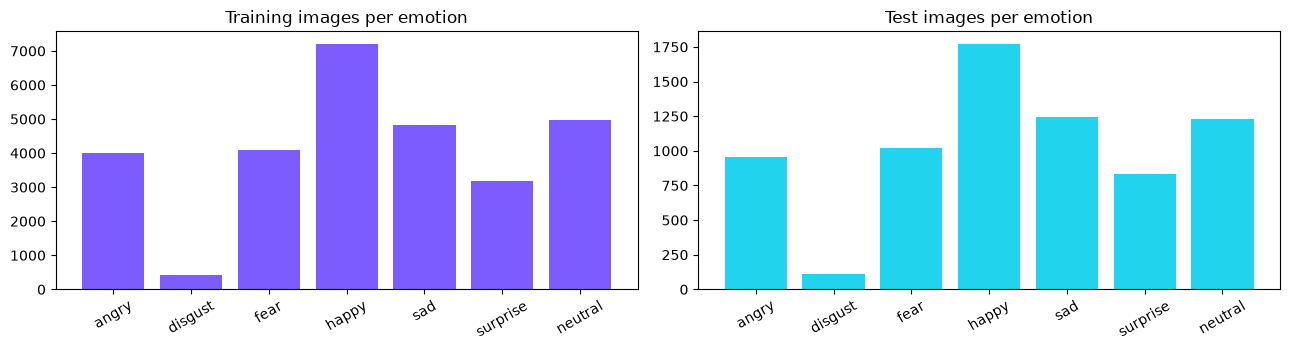

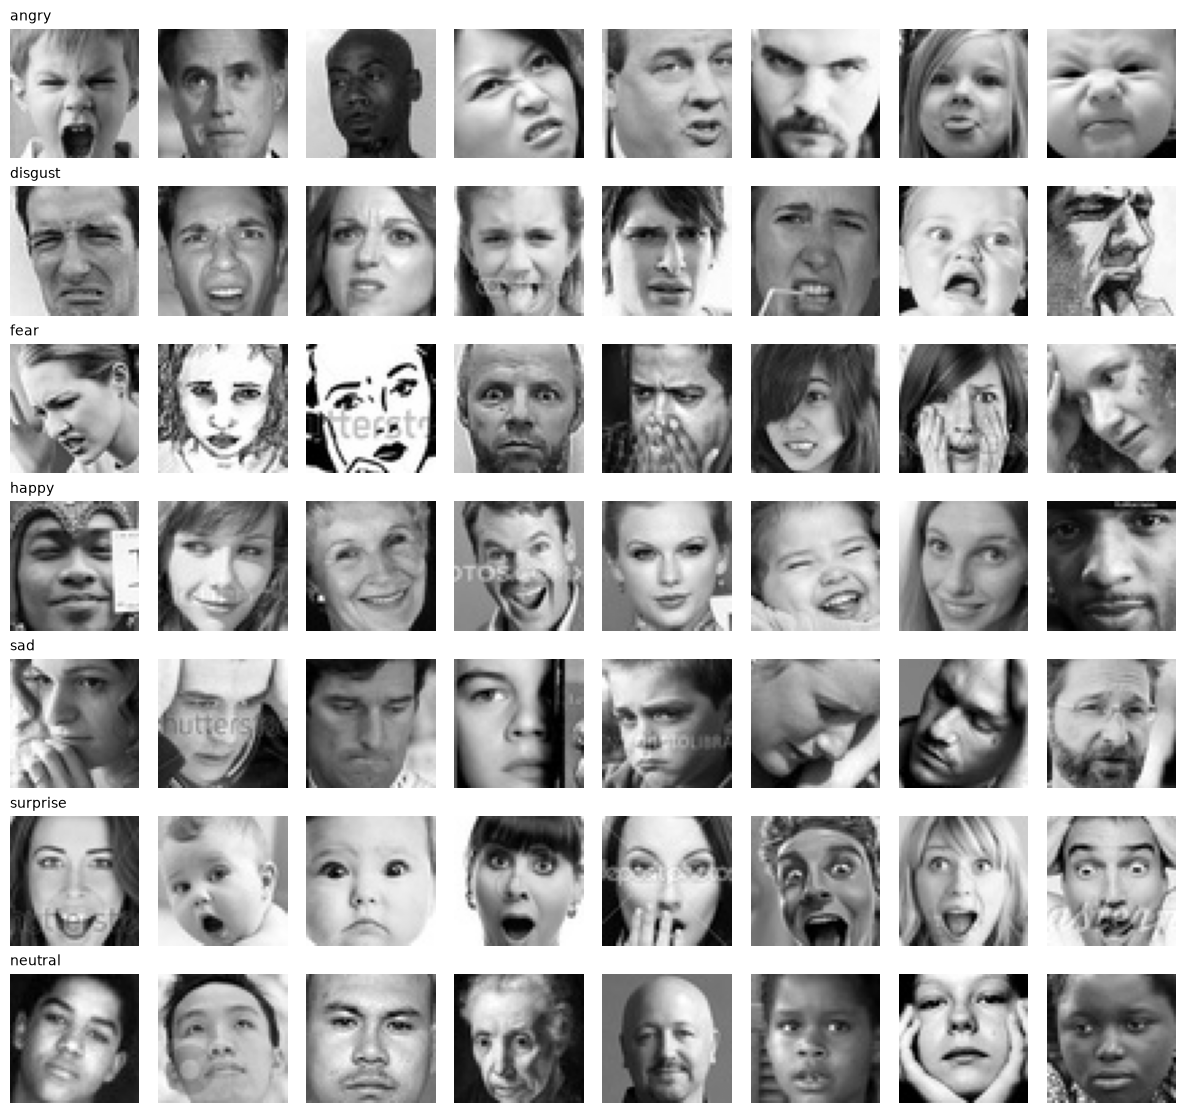

In [6]:
counts_tr = np.bincount(y_train_all, minlength=NUM_CLASSES)
counts_te = np.bincount(y_test, minlength=NUM_CLASSES)
print(pd.DataFrame({"train": counts_tr, "test": counts_te}, index=CLASS_NAMES))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(CLASS_NAMES, counts_tr, color="#7c5cff"); ax[0].set_title("Training images per emotion")
ax[1].bar(CLASS_NAMES, counts_te, color="#22d3ee"); ax[1].set_title("Test images per emotion")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 1.6 * NUM_CLASSES))
for r, c in enumerate(range(NUM_CLASSES)):
    pick = rng.choice(np.where(y_train_all == c)[0], 8, replace=len(np.where(y_train_all == c)[0]) < 8)
    for k, i in enumerate(pick):
        axes[r, k].imshow(X_train_all[i], cmap="gray"); axes[r, k].axis("off")
    axes[r, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## Cell 6 · Train / validation / test split
The original FER-2013 training split is divided into **90% training + 10% validation**
using stratification. The held-out test split remains untouched until final evaluation.

This validation set is important for the fusion notebook because it provides an
independent CNN probability distribution for selecting the fusion weight.

In [18]:
# 90% training + 10% validation split
# Keep the exact image paths so the fusion notebook can reproduce
# the same validation set without recreating the split.

idx_tr, idx_va = train_test_split(
    np.arange(len(y_train_all)),
    test_size=VAL_FRACTION,
    stratify=y_train_all,
    random_state=SEED
)

X_tr, y_tr = X_train_all[idx_tr], y_train_all[idx_tr]
X_va, y_va = X_train_all[idx_va], y_train_all[idx_va]

# ---------------------------------------------------------
# Create exact validation-image manifest for fusion
# ---------------------------------------------------------

MANIFEST_DIR = PROJECT_DIR / "data" / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

if DATA_MODE == "image folders":
    # Recreate the same ordered list used by load_folder_split()
    train_image_paths = []

    for ci, cname in enumerate(CLASS_NAMES):
        folder = DATA_DIR / "train" / cname

        for f in sorted(folder.iterdir()):
            if f.suffix.lower() not in IMAGE_EXTS:
                continue

            train_image_paths.append(
                str(f.relative_to(DATA_DIR)).replace("\\", "/")
            )

    train_image_paths = np.asarray(train_image_paths)

    if len(train_image_paths) != len(y_train_all):
        raise ValueError(
            f"Image-path count ({len(train_image_paths)}) does not match "
            f"training-array count ({len(y_train_all)})."
        )

    validation_manifest = pd.DataFrame({
        "image": train_image_paths[idx_va],
        "emotion": [CLASS_NAMES[i] for i in y_va]
    })

    CNN_VALIDATION_MANIFEST_PATH = (
        MANIFEST_DIR / "cnn_validation_manifest.csv"
    )

    validation_manifest.to_csv(
        CNN_VALIDATION_MANIFEST_PATH,
        index=False
    )

    print("\nCNN validation manifest created:")
    print(CNN_VALIDATION_MANIFEST_PATH)
    print("Validation images:", len(validation_manifest))
    print("\nFirst 5 rows:")
    print(validation_manifest.head())

else:
    raise NotImplementedError(
        "Manifest creation for Kaggle CSV mode has not been added yet. "
        "Your current project uses image-folder mode."
    )

with open(ARTIFACT_DIR / "emotion_labels.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f)

def class_weights(y):
    """Balanced class weights softened with sqrt to avoid unstable rare-class weights."""
    w = compute_class_weight(
        "balanced",
        classes=np.arange(NUM_CLASSES),
        y=y
    )
    return np.sqrt(w).astype("float32")

def make_ds(x, y, weights=None, shuffle=False):
    Y = tf.keras.utils.to_categorical(y, NUM_CLASSES).astype("float32")
    tensors = (x, Y) if weights is None else (x, Y, weights.astype("float32"))

    ds = tf.data.Dataset.from_tensor_slices(tensors)

    if shuffle:
        ds = ds.shuffle(
            min(len(y), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print(f"Train: {len(y_tr)} | Validation: {len(y_va)} | Test: {len(y_test)}")
print("Class weights:", dict(zip(
    CLASS_NAMES,
    class_weights(y_tr).round(2)
)))


CNN validation manifest created:
c:\Users\HP\Documents\MiniProject\data\manifests\cnn_validation_manifest.csv
Validation images: 2871

First 5 rows:
                                 image  emotion
0  train/neutral/Training_99088484.jpg  neutral
1    train/angry/Training_89563369.jpg    angry
2  train/neutral/Training_37585633.jpg  neutral
3    train/happy/Training_73417491.jpg    happy
4      train/sad/Training_26895761.jpg      sad
Train: 25838 | Validation: 2871 | Test: 7178
Class weights: {'angry': np.float32(1.01), 'disgust': np.float32(3.07), 'fear': np.float32(1.0), 'happy': np.float32(0.75), 'sad': np.float32(0.92), 'surprise': np.float32(1.14), 'neutral': np.float32(0.91)}


## Cell 7 · CNN model-building and training helpers

In [8]:
def compile_model(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=["accuracy"],
    )
    return model

def make_callbacks(path, patience, lr_patience=6):
    return [
        callbacks.ModelCheckpoint(str(path), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=patience, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=lr_patience, min_lr=1e-6, verbose=1),
    ]

HISTORY = {}
def plot_history(name):
    h = HISTORY[name]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
    ax[0].set_title(f"{name}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
    ax[1].set_title(f"{name}: loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def conv_bn_act(x, filters):
    x = layers.Conv2D(filters, KERNEL_SIZE, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizers.l2(L2_WEIGHT))(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation(ACTIVATION)(x)

def dense_bn_act(x, units, dropout):
    x = layers.Dense(units, use_bias=False, kernel_initializer="he_normal", kernel_regularizer=regularizers.l2(L2_WEIGHT))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(ACTIVATION)(x)
    return layers.Dropout(dropout)(x)

def cnn_trunk(inp):
    """Rescale -> augmentation (training only) -> 4 conv blocks -> flatten."""
    x = layers.Rescaling(1.0 / 255.0)(inp)
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomRotation(0.04, fill_mode="nearest")(x)
    x = layers.RandomZoom(0.10, fill_mode="nearest")(x)
    x = layers.RandomTranslation(0.08, 0.08, fill_mode="nearest")(x)
    for filters, n_conv, drop in zip(FILTERS, CONV_PER_BLOCK, DROPOUT_CONV):
        for _ in range(n_conv):
            x = conv_bn_act(x, filters)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(drop)(x)
    return layers.Flatten()(x)

def evaluate_probs(y_true, probs):
    pred = probs.argmax(1)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "per_class_f1": {c: float(v) for c, v in zip(CLASS_NAMES, f1_score(y_true, pred, average=None, labels=range(NUM_CLASSES), zero_division=0))},
        "pred": pred,
    }
print("Helpers ready.")

Helpers ready.


## Cell 9 · MODEL 1 — Appearance CNN (pixels)
Deep VGG-style network: **10 conv layers**, filters **64→128→256→512**, 3×3 kernels, BatchNorm + ReLU after every conv, max-pooling and dropout per block, then two dense layers (**512 and 256 perceptrons**) and a 7-way softmax.

In [9]:
def build_appearance_cnn():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 1), name="face")
    x = cnn_trunk(inp)
    for units, drop in zip(DENSE_UNITS, DROPOUT_DENSE):
        x = dense_bn_act(x, units, drop)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="emotion")(x)
    return models.Model(inp, out, name="appearance_cnn")

# Do not instantiate/build the CNN when a trained model will be reused.
# This avoids unnecessary model construction and keeps the reuse path lightweight.
cnn = None

if FORCE_RETRAIN or not CNN_MODEL_PATH.is_file():
    cnn = compile_model(build_appearance_cnn(), CNN_LR)
    print("CNN architecture prepared for training.")
else:
    print("Existing CNN detected; model construction for training is skipped.")


Existing CNN detected; model construction for training is skipped.


### Train once, then reuse the saved appearance CNN
If a trained `appearance_cnn.keras` model is already present, the notebook **loads it
and skips training**. This makes the notebook safe to rerun without spending another
long training session.

Set `FORCE_RETRAIN = True` in the configuration cell only when a fresh training run is
actually needed.

In [10]:
model_exists = CNN_MODEL_PATH.is_file()

if model_exists and not FORCE_RETRAIN:
    print(f"Found trained CNN: {CNN_MODEL_PATH}")
    print("Loading the existing model — training will be skipped.")
    cnn = tf.keras.models.load_model(CNN_MODEL_PATH, compile=False)
    print(f"Loaded model parameters: {cnn.count_params():,}")
    HISTORY.setdefault("Appearance CNN", {})
else:
    print("No reusable CNN model found, or FORCE_RETRAIN=True.")
    print("Training the appearance CNN now...")

    if cnn is None:
        cnn = compile_model(build_appearance_cnn(), CNN_LR)

    ds_tr = make_ds(
        face_tensor(X_tr),
        y_tr,
        weights=class_weights(y_tr)[y_tr],
        shuffle=True
    )
    ds_va = make_ds(face_tensor(X_va), y_va)

    t0 = time.time()
    hist = cnn.fit(
        ds_tr,
        validation_data=ds_va,
        epochs=CNN_EPOCHS,
        callbacks=make_callbacks(CNN_MODEL_PATH, PATIENCE),
        verbose=1
    )
    HISTORY["Appearance CNN"] = hist.history
    cnn.save(CNN_MODEL_PATH)
    print(
        f"\nTraining time: {(time.time() - t0) / 60:.1f} min | "
        f"best val accuracy: {max(hist.history['val_accuracy']) * 100:.2f}%"
    )
    plot_history("Appearance CNN")

print("CNN ready:", CNN_MODEL_PATH)


Found trained CNN: c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras
Loading the existing model — training will be skipped.
Loaded model parameters: 10,137,415
CNN ready: c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras


## Cell 9 · Validate the appearance CNN
Always run this cell, even when the CNN was loaded from disk. It produces the validation
probabilities that the decision-level fusion notebook can use later.

In [12]:
cnn_val_metrics = evaluate_probs(y_va, probs_cnn_val)

print(f"Validation accuracy: {cnn_val_metrics['accuracy'] * 100:.2f}%")
print(f"Validation macro-F1: {cnn_val_metrics['macro_f1']:.3f}")

# Weighted-F1 may not be returned by the current helper
if "weighted_f1" in cnn_val_metrics:
    print(f"Validation weighted-F1: {cnn_val_metrics['weighted_f1']:.3f}")
else:
    weighted_f1 = f1_score(
        y_va,
        np.argmax(probs_cnn_val, axis=1),
        average="weighted"
    )
    print(f"Validation weighted-F1: {weighted_f1:.3f}")

print()

print(classification_report(
    y_va,
    np.argmax(probs_cnn_val, axis=1),
    target_names=CLASS_NAMES,
    digits=3
))

Validation accuracy: 65.90%
Validation macro-F1: 0.610
Validation weighted-F1: 0.658

              precision    recall  f1-score   support

       angry      0.662     0.531     0.590       399
     disgust      0.350     0.477     0.404        44
        fear      0.502     0.505     0.504       410
       happy      0.843     0.889     0.865       722
         sad      0.520     0.528     0.524       483
    surprise      0.757     0.757     0.757       317
     neutral      0.618     0.635     0.626       496

    accuracy                          0.659      2871
   macro avg      0.608     0.618     0.610      2871
weighted avg      0.659     0.659     0.658      2871



## Cell 10 · Final test evaluation
The test set is evaluated only after the CNN has been loaded/trained. These outputs are
kept separate from validation outputs so the fusion notebook can use validation data
for tuning without leaking the test set.

In [14]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

test_pred = probs_cnn_test.argmax(axis=1)

plain_acc = accuracy_score(y_test, probs_cnn_test_plain.argmax(1))
tta_acc = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, test_pred, average="weighted")

print(f"Test accuracy (plain): {plain_acc * 100:.2f}%")
print(f"Test accuracy (+TTA) : {tta_acc * 100:.2f}%")
print(f"Test macro-F1        : {test_macro_f1:.3f}")
print(f"Test weighted-F1     : {test_weighted_f1:.3f}")
print()

print(classification_report(
    y_test,
    test_pred,
    target_names=CLASS_NAMES,
    digits=3
))

Test accuracy (plain): 65.90%
Test accuracy (+TTA) : 67.01%
Test macro-F1        : 0.641
Test weighted-F1     : 0.668

              precision    recall  f1-score   support

       angry      0.636     0.547     0.588       958
     disgust      0.461     0.739     0.567       111
        fear      0.501     0.487     0.494      1024
       happy      0.844     0.890     0.866      1774
         sad      0.553     0.543     0.548      1247
    surprise      0.783     0.761     0.772       831
     neutral      0.640     0.663     0.651      1233

    accuracy                          0.670      7178
   macro avg      0.631     0.661     0.641      7178
weighted avg      0.669     0.670     0.668      7178



## Cell 11 · CNN results and training curves

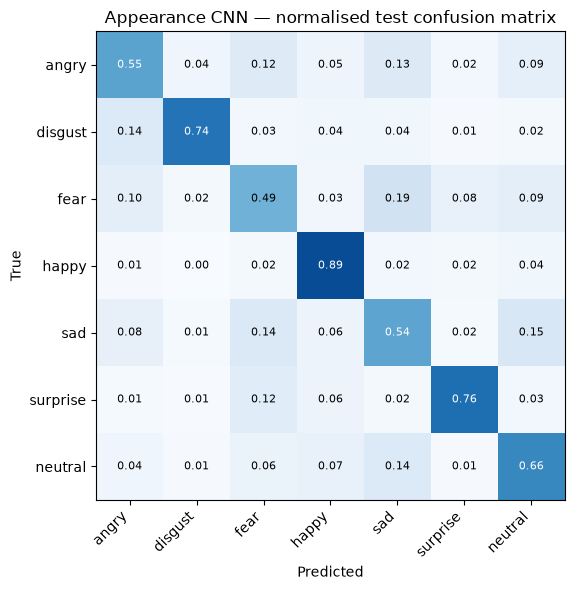

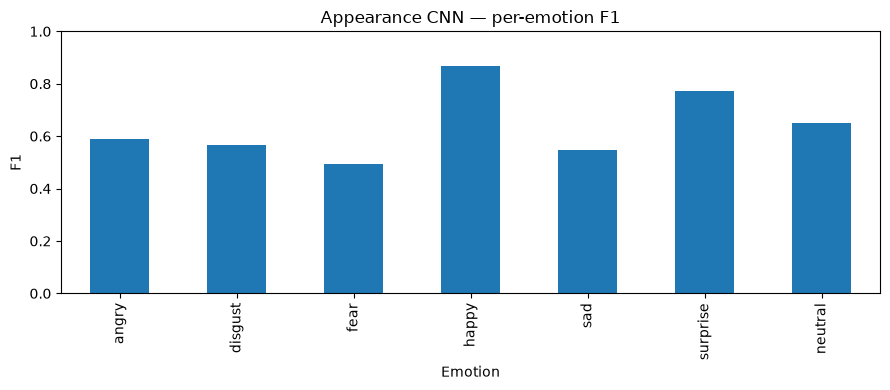

Training history is not available because the CNN was loaded from an existing model.


In [15]:
# Confusion matrix
cm = confusion_matrix(y_test, cnn_test_metrics["pred"], labels=range(NUM_CLASSES))
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Appearance CNN — normalised test confusion matrix")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_CM_DIR / "cnn_confusion_matrix.png", dpi=140)
plt.show()

# Per-class F1
f1_series = pd.Series(cnn_test_metrics["per_class_f1"])
ax = f1_series.plot(kind="bar", figsize=(9, 4), ylim=(0, 1), title="Appearance CNN — per-emotion F1")
ax.set_xlabel("Emotion"); ax.set_ylabel("F1")
plt.tight_layout()
plt.savefig(RESULTS_EXP_DIR / "cnn_per_class_f1.png", dpi=140)
plt.show()

if HISTORY.get("Appearance CNN") and HISTORY["Appearance CNN"].get("val_accuracy"):
    plot_history("Appearance CNN")
else:
    print("Training history is not available because the CNN was loaded from an existing model.")


## Fusion handoff files
These are the files the decision-level fusion notebook can consume.

**Fusion artifacts (authoritative):**
- `artifacts/cnn_validation_predictions.npz`
- `artifacts/cnn_test_predictions.npz`
- `artifacts/cnn_validation_metrics.json`
- `artifacts/cnn_test_metrics.json`
- `models/appearance_cnn_fixed.keras` (or the existing CNN model selected above)

**Project results copies:**
- `results/predictions/`
- `results/experiments/`
- `results/confusion_matrices/`

The geometry branch remains completely separate and is produced by
`Geometry_Branch.ipynb`.

In [16]:
handoff = {
    "project_root": str(PROJECT_DIR),
    "dataset": str(DATA_DIR),
    "cnn_model": str(CNN_MODEL_PATH),
    "validation_predictions": str(CNN_VALIDATION_PRED_PATH),
    "validation_metrics": str(CNN_VALIDATION_METRICS),
    "test_predictions": str(CNN_TEST_PRED_PATH),
    "test_metrics": str(CNN_TEST_METRICS),
    "results_predictions_dir": str(RESULTS_PRED_DIR),
    "results_experiments_dir": str(RESULTS_EXP_DIR),
    "labels": str(ARTIFACT_DIR / "emotion_labels.json"),
    "class_order": CLASS_NAMES,
}
print(json.dumps(handoff, indent=2))

print("\nCNN appearance branch is complete.")
print("Next notebook: Geometry_Branch.ipynb")
print("After that: fusion/Decision_Level_Fusion.ipynb")


{
  "project_root": "c:\\Users\\HP\\Documents\\MiniProject",
  "dataset": "c:\\Users\\HP\\Documents\\MiniProject\\data\\FER-2013",
  "cnn_model": "c:\\Users\\HP\\Documents\\MiniProject\\models\\appearance_cnn_fixed.keras",
  "validation_predictions": "c:\\Users\\HP\\Documents\\MiniProject\\artifacts\\cnn_validation_predictions.npz",
  "validation_metrics": "c:\\Users\\HP\\Documents\\MiniProject\\artifacts\\cnn_validation_metrics.json",
  "test_predictions": "c:\\Users\\HP\\Documents\\MiniProject\\artifacts\\cnn_test_predictions.npz",
  "test_metrics": "c:\\Users\\HP\\Documents\\MiniProject\\artifacts\\cnn_test_metrics.json",
  "results_predictions_dir": "c:\\Users\\HP\\Documents\\MiniProject\\results\\predictions",
  "results_experiments_dir": "c:\\Users\\HP\\Documents\\MiniProject\\results\\experiments",
  "labels": "c:\\Users\\HP\\Documents\\MiniProject\\artifacts\\emotion_labels.json",
  "class_order": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",

## Cell 13 · Verify CNN artifacts
This cell does not retrain anything. It only checks that the files needed by the next
fusion stage were successfully created.

In [17]:
required_files = [
    CNN_MODEL_PATH,
    CNN_VALIDATION_PRED_PATH,
    CNN_VALIDATION_METRICS,
    CNN_TEST_PRED_PATH,
    CNN_TEST_METRICS,
    CNN_VAL_RESULTS_PATH,
    CNN_TEST_RESULTS_PATH,
    CNN_VAL_METRICS_RESULTS,
    CNN_TEST_METRICS_RESULTS,
    ARTIFACT_DIR / "emotion_labels.json",
]

for p in required_files:
    print(("OK      " if p.is_file() else "MISSING ") + str(p))

print("\nProject structure check:")
print("  Dataset :", DATA_DIR)
print("  Model   :", CNN_MODEL_PATH)
print("  Results :", RESULTS_DIR)
print("  Fusion  :", PROJECT_DIR / "fusion")


OK      c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras
MISSING c:\Users\HP\Documents\MiniProject\artifacts\cnn_validation_predictions.npz
MISSING c:\Users\HP\Documents\MiniProject\artifacts\cnn_validation_metrics.json
MISSING c:\Users\HP\Documents\MiniProject\artifacts\cnn_test_predictions.npz
MISSING c:\Users\HP\Documents\MiniProject\artifacts\cnn_test_metrics.json
MISSING c:\Users\HP\Documents\MiniProject\results\predictions\cnn_validation_predictions.npz
MISSING c:\Users\HP\Documents\MiniProject\results\predictions\cnn_test_predictions.npz
MISSING c:\Users\HP\Documents\MiniProject\results\experiments\cnn_validation_metrics.json
MISSING c:\Users\HP\Documents\MiniProject\results\experiments\cnn_test_metrics.json
OK      c:\Users\HP\Documents\MiniProject\artifacts\emotion_labels.json

Project structure check:
  Dataset : c:\Users\HP\Documents\MiniProject\data\FER-2013
  Model   : c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras
  Results : c:\Use

## Next step

After this notebook finishes successfully, run `Geometry_Branch.ipynb` separately.

Then use `fusion/Decision_Level_Fusion.ipynb` to combine the CNN artifacts from
`artifacts/` with the geometry artifacts.

The appearance CNN is **not retrained** unless `FORCE_RETRAIN = True`.
